In [1]:
# ============ Cell 1: load & pre-process ============
import numpy as np
import pandas as pd

DATA = r"C:\Users\lin\Desktop\6067B\PART 2\个人项目\01_DID\01_DID\data\public.csv"
df = pd.read_csv(DATA)

# Pre-process: coerce analysis columns to numeric (blank -> NaN).
num_cols = [
    "CHAIN", "CO_OWNED", "STATE",
    "EMPFT", "EMPPT", "NMGRS", "WAGE_ST", "BONUS", "HRSOPEN",
    "PSODA", "PFRY", "PENTREE",
    "STATUS2",
    "EMPFT2", "EMPPT2", "NMGRS2", "WAGE_ST2", "SPECIAL2", "HRSOPEN2",
    "PSODA2", "PFRY2", "PENTREE2",
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Group masks (rule 4): STATE==1 -> NJ, STATE==0 -> PA
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

In [10]:
# ============ Cell 2: derived quantities (do NOT modify df) ============
# rule 2: wave-1 FTE = full-time INCLUDING managers + 0.5 * part-time
fte = df["NMGRS"] + df["EMPFT"] + 0.5 * df["EMPPT"]

# rule 3 (critical): wave-2 FTE special handling
fte2_raw = df["NMGRS2"] + df["EMPFT2"] + 0.5 * df["EMPPT2"]
fte2 = pd.Series(np.nan, index=df.index)                              # default: NaN
fte2[df["STATUS2"] == 1] = fte2_raw[df["STATUS2"] == 1]               # interviewed -> formula
fte2[df["STATUS2"] == 3] = 0.0                                        # permanently closed -> 0
# STATUS2 in [2,4,5] (temporary), ==0 (refused), other -> NaN (default)

# Percentage full-time employees (%): full-time (INCLUDING managers, per paper
# footnote) as a share of all employees = (full-time + managers) / (full + part + managers).
pct_full  = 100.0 * (df["EMPFT"]  + df["NMGRS"])  / (df["EMPFT"]  + df["EMPPT"]  + df["NMGRS"])
pct_full2 = 100.0 * (df["EMPFT2"] + df["NMGRS2"]) / (df["EMPFT2"] + df["EMPPT2"] + df["NMGRS2"])

# Price of full meal = soda + fries + entree (incl. tax)
mealp  = df["PSODA"]  + df["PFRY"]  + df["PENTREE"]
mealp2 = df["PSODA2"] + df["PFRY2"] + df["PENTREE2"]

# Store type / ownership 0-1 indicators (CHAIN, CO_OWNED complete)
bk  = (df["CHAIN"] == 1).astype(float)
kfc = (df["CHAIN"] == 2).astype(float)
rr  = (df["CHAIN"] == 3).astype(float)
wd  = (df["CHAIN"] == 4).astype(float)
co  = (df["CO_OWNED"] == 1).astype(float)

# Wage == $4.25 / $5.05 indicators (only over non-missing wage)
w425  = np.where(df["WAGE_ST"].notna(),  (df["WAGE_ST"]  == 4.25).astype(float), np.nan)
w4252 = np.where(df["WAGE_ST2"].notna(), (df["WAGE_ST2"] == 4.25).astype(float), np.nan)
w5052 = np.where(df["WAGE_ST2"].notna(), (df["WAGE_ST2"] == 5.05).astype(float), np.nan)

# Recruiting bonus: wave1 = BONUS, wave2 = SPECIAL2
bonus    = np.where(df["BONUS"].notna(),    (df["BONUS"]    == 1).astype(float), np.nan)
special2 = np.where(df["SPECIAL2"].notna(), (df["SPECIAL2"] == 1).astype(float), np.nan)

In [ ]:
·# ============ Cell 3: statistics & Table 2 output (numpy-only, no scipy) ============
def mean_se(x):
    """rule 1: mean & standard error over NON-MISSING values of this variable only."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = x.size
    if n == 0:
        return np.nan, np.nan, 0
    m = x.mean()
    s = x.std(ddof=1) if n > 1 else np.nan
    se = s / np.sqrt(n) if n > 1 else np.nan
    return m, se, n

# rows: (section, label, values, scale100, decimals)
rows = []
def add(section, label, v, scale100=False, ndec=2):
    v = np.asarray(v, dtype=float)
    rows.append((section, label, v[nj], v[pa], scale100, ndec))

A = "A. Distribution of Store Types (%)"
add(A, "Burger King",   bk,  scale100=True, ndec=1)
add(A, "KFC",           kfc, scale100=True, ndec=1)
add(A, "Roy Rogers",    rr,  scale100=True, ndec=1)
add(A, "Wendy's",       wd,  scale100=True, ndec=1)
add(A, "Company-owned", co,  scale100=True, ndec=1)

B = "B. Means in Wave 1 (pre-policy)"
add(B, "FTE employment",                 fte,           ndec=2)
add(B, "Percentage full-time employees", pct_full,      ndec=1)
add(B, "Starting wage",                  df["WAGE_ST"], ndec=2)
add(B, "Wage = $4.25 (%)",               w425, scale100=True, ndec=1)
add(B, "Price of full meal",             mealp,         ndec=2)
add(B, "Hours open (weekday)",           df["HRSOPEN"], ndec=2)
add(B, "Recruiting bonus (%)",           bonus, scale100=True, ndec=1)

C = "C. Means in Wave 2 (post-policy)"
add(C, "FTE employment",                 fte2,           ndec=2)
add(C, "Percentage full-time employees", pct_full2,      ndec=1)
add(C, "Starting wage",                  df["WAGE_ST2"], ndec=2)
add(C, "Wage = $4.25 (%)",               w4252, scale100=True, ndec=1)
add(C, "Wage = $5.05 (%)",               w5052, scale100=True, ndec=1)
add(C, "Price of full meal",             mealp2,         ndec=2)
add(C, "Hours open (weekday)",           df["HRSOPEN2"], ndec=2)
add(C, "Recruiting bonus (%)",           special2, scale100=True, ndec=1)

idx, data, ns = [], [], []
for section, label, vn, vp, scale100, ndec in rows:
    mn, sen, nn = mean_se(vn)
    mp, sep, np_ = mean_se(vp)
    # Welch two-sample t-statistic, H0: mean(NJ) = mean(PA)
    t = (mn - mp) / np.sqrt(sen**2 + sep**2)
    if scale100:
        mn, sen, mp, sep = mn*100, sen*100, mp*100, sep*100
    idx.append((section, label))
    data.append([f"{mn:.{ndec}f} ({sen:.{ndec}f})",
                 f"{mp:.{ndec}f} ({sep:.{ndec}f})",
                 f"{t:.2f}"])
    ns.append([nn, np_])

out = pd.DataFrame(data,
                   index=pd.MultiIndex.from_tuples(idx),
                   columns=["New Jersey", "Pennsylvania", "t-statistic"])
print(out.to_string())

print("\nSample sizes (non-missing per variable, NJ / PA):")
print(pd.DataFrame(ns, index=pd.MultiIndex.from_tuples(idx),
                   columns=["N_NJ", "N_PA"]).to_string())

                                                                     New Jersey  Pennsylvania t-statistic
A. Distribution of Store Types (%) Burger King                       41.1 (2.7)    44.3 (5.6)       -0.52
                                   KFC                               20.5 (2.2)    15.2 (4.1)        1.16
                                   Roy Rogers                        24.8 (2.4)    21.5 (4.7)        0.62
                                   Wendy's                           13.6 (1.9)    19.0 (4.4)       -1.12
                                   Company-owned                     34.1 (2.6)    35.4 (5.4)       -0.22
B. Means in Wave 1 (pre-policy)    FTE employment                  20.44 (0.51)  23.33 (1.35)       -2.00
                                   Percentage full-time employees    37.7 (1.1)    38.8 (2.3)       -0.40
                                   Starting wage                    4.61 (0.02)   4.63 (0.04)       -0.40
                                   Wage = $4.2

In [3]:
# ============================================================
# 诊断单元格：定位 Table 2 "Percentage full-time employees" 的定义
# 原文目标值（括号内为 SE）：
#   wave 1:  NJ 32.8 (1.3)   PA 35.0 (2.7)
#   wave 2:  NJ 35.9 (1.4)   PA 30.4 (2.8)
# 记 F = EMPFT, P = EMPPT, M = NMGRS
# 候选通式: 100 * (F + a*M) / (F + P + b*M)
# ============================================================

TARGET = {"NJ_w1": "32.8 (1.3)", "PA_w1": "35.0 (2.7)",
          "NJ_w2": "35.9 (1.4)", "PA_w2": "30.4 (2.8)"}


def series_for(state, wave):
    """取某州某轮的 (EMPFT, EMPPT, NMGRS)。wave2 只保留成功回访(STATUS2==1)的门店。"""
    sub = df[df["STATE"] == state]
    if wave == 1:
        return (sub["EMPFT"].to_numpy(float),
                sub["EMPPT"].to_numpy(float),
                sub["NMGRS"].to_numpy(float))
    sub = sub[sub["STATUS2"] == 1]
    return (sub["EMPFT2"].to_numpy(float),
            sub["EMPPT2"].to_numpy(float),
            sub["NMGRS2"].to_numpy(float))


def _prep(F, P, M, a, b):
    F = np.asarray(F, float); P = np.asarray(P, float); M = np.asarray(M, float)
    ok = np.isfinite(F) & np.isfinite(P)
    if a != 0.0 or b != 0.0:          # 只用得到 M 的方案才要求 M 非缺失
        ok &= np.isfinite(M)
    return F[ok], P[ok], M[ok]


def pct_per_store(F, P, M, a, b):
    """先算每家店的百分比，再对门店求均值 (mean of ratios)。"""
    F, P, M = _prep(F, P, M, a, b)
    den = F + P + b * M
    r = np.where(den > 0, 100.0 * (F + a * M) / den, np.nan)
    r = r[np.isfinite(r)]
    n = r.size
    return r.mean(), r.std(ddof=1) / np.sqrt(n), n


def pct_aggregate(F, P, M, a, b):
    """先合并总量再作比 (ratio of means)。"""
    F, P, M = _prep(F, P, M, a, b)
    val = 100.0 * (F.mean() + a * M.mean()) / (F.mean() + P.mean() + b * M.mean())
    return val, F.size


CANDS = [
    ("F / (F+P)",            0.0, 0.0),
    ("(F+M) / (F+P+M)",      1.0, 1.0),
    ("(F+M) / (F+P)",        1.0, 0.0),
    ("(F+0.5M) / (F+P)",     0.5, 0.0),
    ("(F+0.5M) / (F+P+0.5M)",0.5, 0.5),
    ("F / (F+P+M)",          0.0, 1.0),
]

hdr = (f"{'definition':26s} | {'NJ w1':>13s} | {'PA w1':>13s} | "
       f"{'NJ w2':>13s} | {'PA w2':>13s}")
bar = "-" * len(hdr)

print(hdr); print(bar)
print(f"{'*** PAPER TABLE 2 ***':26s} | {TARGET['NJ_w1']:>13s} | "
      f"{TARGET['PA_w1']:>13s} | {TARGET['NJ_w2']:>13s} | {TARGET['PA_w2']:>13s}")
print(bar)

print("[A] mean of ratios  (先算每店比例，再平均；括号内为 SE)")
for name, a, b in CANDS:
    row = []
    for wave in (1, 2):
        for st in (1, 0):
            F, P, M = series_for(st, wave)
            m, s, _ = pct_per_store(F, P, M, a, b)
            row.append(f"{m:.1f} ({s:.1f})")
    print(f"{name:26s} | {row[0]:>13s} | {row[1]:>13s} | {row[2]:>13s} | {row[3]:>13s}")

print()
print("[B] ratio of means  (先合并总量，再作比；括号内为 n)")
for name, a, b in CANDS:
    row = []
    for wave in (1, 2):
        for st in (1, 0):
            F, P, M = series_for(st, wave)
            m, n = pct_aggregate(F, P, M, a, b)
            row.append(f"{m:.1f} (n={n})")
    print(f"{name:26s} | {row[0]:>13s} | {row[1]:>13s} | {row[2]:>13s} | {row[3]:>13s}")

print()
print("非缺失样本量：")
for wave in (1, 2):
    for st, sname in ((1, "NJ"), (0, "PA")):
        F, P, M = series_for(st, wave)
        _, _, n = pct_per_store(F, P, M, 0, 0)
        print(f"  {sname} wave{wave}: n = {n}")

definition                 |         NJ w1 |         PA w1 |         NJ w2 |         PA w2
------------------------------------------------------------------------------------------
*** PAPER TABLE 2 ***      |    32.8 (1.3) |    35.0 (2.7) |    35.9 (1.4) |    30.4 (2.8)
------------------------------------------------------------------------------------------
[A] mean of ratios  (先算每店比例，再平均；括号内为 SE)
F / (F+P)                  |    28.6 (1.3) |    29.9 (2.7) |    32.1 (1.4) |    26.0 (2.8)
(F+M) / (F+P+M)            |    37.7 (1.1) |    38.8 (2.3) |    40.8 (1.3) |    35.6 (2.4)
(F+M) / (F+P)              |    43.7 (1.4) |    44.2 (2.6) |    47.6 (1.6) |    40.9 (2.7)
(F+0.5M) / (F+P)           |    36.1 (1.3) |    37.1 (2.6) |    39.9 (1.5) |    33.5 (2.7)
(F+0.5M) / (F+P+0.5M)      |    33.5 (1.2) |    34.7 (2.5) |    36.8 (1.3) |    31.2 (2.6)
F / (F+P+M)                |    24.9 (1.1) |    26.6 (2.4) |    27.8 (1.2) |    23.0 (2.5)

[B] ratio of means  (先合并总量，再作比；括号内为 n)
F / (F+P)

In [5]:
# ============================================================
# 诊断 #2：在 100*(F+a*M)/(F+P+b*M) 的 (a,b) 网格上定位原文定义
# 目标: NJ w1 32.8 | PA w1 35.0 | NJ w2 35.9 | PA w2 30.4
# ============================================================
TGT = [((1, 1), 32.8), ((0, 1), 35.0), ((1, 2), 35.9), ((0, 2), 30.4)]


def get_counts(state, wave, mode="answered"):
    """取某州某轮的 (F, P, M)。mode 只影响 wave2 的样本口径。"""
    sub = df[df["STATE"] == state]
    if wave == 1:
        F, P, M = sub["EMPFT"], sub["EMPPT"], sub["NMGRS"]
    else:
        if mode == "answered":              # 只保留成功回访的门店
            sub = sub[sub["STATUS2"] == 1]
        F, P, M = sub["EMPFT2"], sub["EMPPT2"], sub["NMGRS2"]
    F = F.to_numpy(float); P = P.to_numpy(float); M = M.to_numpy(float)
    ok = np.isfinite(F) & np.isfinite(P) & np.isfinite(M)
    return F[ok], P[ok], M[ok]


def per_store(F, P, M, a, b, drop_zero_F=False):
    """先算每家店的百分比，再对门店求均值。"""
    den = F + P + b * M
    r = np.where(den > 0, 100.0 * (F + a * M) / den, np.nan)
    if drop_zero_F:                          # 假设：剔除 EMPFT==0 的门店
        r = np.where(F > 0, r, np.nan)
    r = r[np.isfinite(r)]
    n = r.size
    return r.mean(), r.std(ddof=1) / np.sqrt(n), n


# ---------- (1) 细网格搜索 ----------
grid = [i / 8 for i in range(9)]             # 0, .125, .25, ..., 1.0
hits = []
for a in grid:
    for b in grid:
        vals, errs = [], []
        for (st, wv), tgt in TGT:
            F, P, M = get_counts(st, wv)
            m, s, _ = per_store(F, P, M, a, b)
            vals.append((m, s)); errs.append(abs(m - tgt))
        hits.append((max(errs), a, b, vals))
hits.sort(key=lambda x: x[0])

hdr = (f"{'max|err|':>8s} | {'a':>5s} | {'b':>5s} | {'NJ w1':>13s} | "
       f"{'PA w1':>13s} | {'NJ w2':>13s} | {'PA w2':>13s}")
bar = "-" * len(hdr)
print(f"{'TARGET':>8s} | {'':>5s} | {'':>5s} | {'32.8 (1.3)':>13s} | "
      f"{'35.0 (2.7)':>13s} | {'35.9 (1.4)':>13s} | {'30.4 (2.8)':>13s}")
print(hdr); print(bar)
for err, a, b, vals in hits[:10]:
    cells = " | ".join(f"{m:6.1f} ({s:4.1f})" for m, s in vals)
    print(f"{err:8.2f} | {a:5.3f} | {b:5.3f} | {cells}")

# ---------- (2) 口径假设检验（固定 a=b=0，即纯 F/(F+P)） ----------
print()
print("样本口径假设检验（a=b=0, 100*F/(F+P)）：")
def show(tag, mode, drop_zero):
    out = []
    for (st, wv), tgt in TGT:
        F, P, M = get_counts(st, wv, mode=mode)
        m, s, n = per_store(F, P, M, 0.0, 0.0, drop_zero_F=drop_zero)
        out.append(f"{m:6.1f} ({s:4.1f}) n={n}")
    print(f"  {tag:34s} " + " | ".join(out))

show("baseline: answered, keep F==0",   "answered", False)
show("drop stores with EMPFT == 0",     "answered", True)
show("wave2 = all non-missing",         "all",      False)
show("wave2 = all non-missing, dropF0", "all",      True)

  TARGET |       |       |    32.8 (1.3) |    35.0 (2.7) |    35.9 (1.4) |    30.4 (2.8)
max|err| |     a |     b |         NJ w1 |         PA w1 |         NJ w2 |         PA w2
----------------------------------------------------------------------------------------
    0.81 | 0.625 | 1.000 |   32.9 ( 1.1) |   34.2 ( 2.3) |   35.9 ( 1.2) |   30.9 ( 2.4)
    0.85 | 0.500 | 0.625 |   32.9 ( 1.2) |   34.1 ( 2.4) |   36.1 ( 1.3) |   30.7 ( 2.5)
    0.89 | 0.500 | 0.500 |   33.5 ( 1.2) |   34.7 ( 2.5) |   36.8 ( 1.3) |   31.2 ( 2.6)
    0.90 | 0.375 | 0.250 |   33.0 ( 1.2) |   34.1 ( 2.5) |   36.4 ( 1.4) |   30.5 ( 2.6)
    0.96 | 0.625 | 0.875 |   33.5 ( 1.1) |   34.7 ( 2.4) |   36.5 ( 1.3) |   31.4 ( 2.4)
    1.25 | 0.375 | 0.125 |   33.6 ( 1.3) |   34.7 ( 2.6) |   37.1 ( 1.4) |   31.1 ( 2.7)
    1.36 | 0.500 | 0.750 |   32.4 ( 1.2) |   33.6 ( 2.4) |   35.5 ( 1.3) |   30.2 ( 2.5)
    1.44 | 0.375 | 0.375 |   32.4 ( 1.2) |   33.6 ( 2.5) |   35.7 ( 1.3) |   30.0 ( 2.6)
    1.46 | 0.625 | 0.

C:\Users\lin\AppData\Local\Temp\ipykernel_37820\4224354650.py:25: RuntimeWarning: invalid value encountered in divide
  r = np.where(den > 0, 100.0 * (F + a * M) / den, np.nan)


In [2]:
# ============================================================
# 诊断 #3：零值门店口径 + 经理权重 联合搜索
# 目标: NJ w1 32.8 (1.3) | PA w1 35.0 (2.7)
#       NJ w2 35.9 (1.4) | PA w2 30.4 (2.8)
# ============================================================
TGT = [((1, 1), 32.8), ((0, 1), 35.0), ((1, 2), 35.9), ((0, 2), 30.4)]


def get_counts(state, wave):
    """取某州某轮的 (F, P, M)；wave2 只保留成功回访(STATUS2==1)门店。"""
    sub = df[df["STATE"] == state]
    if wave == 1:
        F, P, M = sub["EMPFT"], sub["EMPPT"], sub["NMGRS"]
    else:
        sub = sub[sub["STATUS2"] == 1]
        F, P, M = sub["EMPFT2"], sub["EMPPT2"], sub["NMGRS2"]
    F = F.to_numpy(float); P = P.to_numpy(float); M = M.to_numpy(float)
    ok = np.isfinite(F) & np.isfinite(P) & np.isfinite(M)
    return F[ok], P[ok], M[ok]


def stat(F, P, M, a, b, drop_F0, drop_P0):
    """先算每家店的百分比，再对门店求均值；drop_*0 控制分母/分子为 0 的店是否剔除。"""
    den = F + P + b * M
    r = np.where(den > 0, 100.0 * (F + a * M) / den, np.nan)
    if drop_F0:
        r = np.where(F > 0, r, np.nan)       # 剔除无全职员工的门店
    if drop_P0:
        r = np.where(P > 0, r, np.nan)       # 剔除无兼职员工的门店
    r = r[np.isfinite(r)]
    n = r.size
    return r.mean(), r.std(ddof=1) / np.sqrt(n), n


# ---------- 先看看零值门店到底有多少 ----------
print("zero counts:")
for wave in (1, 2):
    for st, name in ((1, "NJ"), (0, "PA")):
        F, P, M = get_counts(st, wave)
        print(f"  {name} wave{wave}: n={F.size:3d} | EMPFT==0: {(F == 0).sum():3d} "
              f"| EMPPT==0: {(P == 0).sum():3d} | both==0: {((F == 0) & (P == 0)).sum():3d}")

# ---------- 联合网格搜索 ----------
res = []
grid = [i / 8 for i in range(9)]
for drop_F0 in (False, True):
    for drop_P0 in (False, True):
        for a in grid:
            for b in grid:
                vals, errs = [], []
                for (st, wv), tgt in TGT:
                    F, P, M = get_counts(st, wv)
                    m, s, n = stat(F, P, M, a, b, drop_F0, drop_P0)
                    vals.append((m, s)); errs.append(abs(m - tgt))
                res.append((max(errs), drop_F0, drop_P0, a, b, vals))
res.sort(key=lambda x: x[0])

hdr = (f"{'max|err|':>8s} | {'dropF0':>6s} | {'dropP0':>6s} | {'a':>5s} | {'b':>5s} | "
       f"{'NJ w1':>13s} | {'PA w1':>13s} | {'NJ w2':>13s} | {'PA w2':>13s}")
print()
print(f"{'TARGET':>8s} | {'':>6s} | {'':>6s} | {'':>5s} | {'':>5s} | "
      f"{'32.8 (1.3)':>13s} | {'35.0 (2.7)':>13s} | {'35.9 (1.4)':>13s} | {'30.4 (2.8)':>13s}")
print("-" * len(hdr))
for err, kf, kp, a, b, vals in res[:12]:
    cells = " | ".join(f"{m:6.1f} ({s:4.1f})" for m, s in vals)
    print(f"{err:8.2f} | {str(kf):>6s} | {str(kp):>6s} | {a:5.3f} | {b:5.3f} | {cells}")

zero counts:
  NJ wave1: n=321 | EMPFT==0:  64 | EMPPT==0:   1 | both==0:   0
  PA wave1: n= 77 | EMPFT==0:   9 | EMPPT==0:   0 | both==0:   0
  NJ wave2: n=314 | EMPFT==0:  52 | EMPPT==0:   3 | both==0:   0
  PA wave2: n= 76 | EMPFT==0:  17 | EMPPT==0:   0 | both==0:   0

  TARGET |        |        |       |       |    32.8 (1.3) |    35.0 (2.7) |    35.9 (1.4) |    30.4 (2.8)
----------------------------------------------------------------------------------------------------------
    0.66 |  False |   True | 0.375 | 0.125 |   33.4 ( 1.3) |   34.7 ( 2.6) |   36.4 ( 1.4) |   31.1 ( 2.7)
    0.81 |  False |  False | 0.625 | 1.000 |   32.9 ( 1.1) |   34.2 ( 2.3) |   35.9 ( 1.2) |   30.9 ( 2.4)
    0.81 |  False |   True | 0.625 | 1.000 |   32.7 ( 1.1) |   34.2 ( 2.3) |   35.4 ( 1.2) |   30.9 ( 2.4)
    0.82 |  False |   True | 0.500 | 0.500 |   33.3 ( 1.2) |   34.7 ( 2.5) |   36.2 ( 1.3) |   31.2 ( 2.6)
    0.85 |  False |  False | 0.500 | 0.625 |   32.9 ( 1.2) |   34.1 ( 2.4) |   36.1 

In [2]:
# ============ Cell 1: load & pre-process ============
import numpy as np
import pandas as pd

DATA = r"C:\Users\lin\Desktop\6067B\PART 2\个人项目\01_DID\01_DID\data\public.csv"
df = pd.read_csv(DATA)

# Pre-process: coerce analysis columns to numeric (blank -> NaN).
num_cols = [
    "CHAIN", "CO_OWNED", "STATE",
    "EMPFT", "EMPPT", "NMGRS", "WAGE_ST", "BONUS", "HRSOPEN",
    "PSODA", "PFRY", "PENTREE",
    "STATUS2",
    "EMPFT2", "EMPPT2", "NMGRS2", "WAGE_ST2", "SPECIAL2", "HRSOPEN2",
    "PSODA2", "PFRY2", "PENTREE2",
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Group masks (rule 4): STATE==1 -> NJ, STATE==0 -> PA
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

In [3]:
# ============================================================
# Cell 2: derived variables  (do NOT modify df)
# Reference: Card & Krueger (1994), Table 2
# ============================================================

# --- FTE employment (full-time-equivalent) ---
# Paper footnote: FTE = full-time workers (INCLUDING managers) + 0.5 * part-time
fte  = df["NMGRS"]  + df["EMPFT"]  + 0.5 * df["EMPPT"]

# Wave-2 FTE with STATUS2 handling:
#   STATUS2 == 3 (permanently closed)            -> fte2 = 0
#   STATUS2 in [2,4,5] (temporarily closed)      -> fte2 = NaN
#   STATUS2 == 1 (successfully interviewed)      -> NMGRS2 + EMPFT2 + 0.5*EMPPT2
#   otherwise                                     -> NaN
fte2_raw = df["NMGRS2"] + df["EMPFT2"] + 0.5 * df["EMPPT2"]
fte2 = pd.Series(np.nan, index=df.index)
fte2[df["STATUS2"] == 1] = fte2_raw[df["STATUS2"] == 1]
fte2[df["STATUS2"] == 3] = 0.0

# --- Percentage full-time employees ---
# full-time share of NON-managerial workers: 100 * EMPFT / (EMPFT + EMPPT)
# (managers excluded; they enter the FTE row above).
# NOTE: per-store SD here reproduces the paper's SEs exactly (1.3/2.7/1.4/2.8);
# public.csv yields a level ~4 pp below the published means (data vintage).
pct_full  = 100.0 * df["EMPFT"]  / (df["EMPFT"]  + df["EMPPT"])
pct_full2 = pd.Series(np.nan, index=df.index)
_ok2 = df["STATUS2"] == 1                     # wave-2: interviewed stores only
pct_full2[_ok2] = 100.0 * df.loc[_ok2, "EMPFT2"] / (
    df.loc[_ok2, "EMPFT2"] + df.loc[_ok2, "EMPPT2"])

# --- Price of a full meal = entree + small fries + medium soda (incl. tax) ---
mealp  = df["PSODA"]  + df["PFRY"]  + df["PENTREE"]
mealp2 = df["PSODA2"] + df["PFRY2"] + df["PENTREE2"]

# --- Store type / ownership indicators (percent of stores) ---
bk  = (df["CHAIN"]    == 1).astype(float)
kfc = (df["CHAIN"]    == 2).astype(float)
rr  = (df["CHAIN"]    == 3).astype(float)
wd  = (df["CHAIN"]    == 4).astype(float)
co  = (df["CO_OWNED"] == 1).astype(float)

# --- Wage dummy indicators (percent, within non-missing wage sample) ---
w425  = np.where(df["WAGE_ST"].notna(),  (df["WAGE_ST"]  == 4.25).astype(float), np.nan)
w4252 = np.where(df["WAGE_ST2"].notna(), (df["WAGE_ST2"] == 4.25).astype(float), np.nan)
w5052 = np.where(df["WAGE_ST2"].notna(), (df["WAGE_ST2"] == 5.05).astype(float), np.nan)

# --- Recruiting bonus / special program (percent) ---
bonus    = np.where(df["BONUS"].notna(),    (df["BONUS"]    == 1).astype(float), np.nan)
special2 = np.where(df["SPECIAL2"].notna(), (df["SPECIAL2"] == 1).astype(float), np.nan)


In [4]:
# ============================================================
# Cell 3: Table 2 statistics and output (all English)
# Per-variable non-missing means; Welch two-sample t-test.
# ============================================================

def mean_se(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = x.size
    if n == 0:
        return np.nan, np.nan, 0
    m = x.mean()
    s = x.std(ddof=1) if n > 1 else np.nan
    se = s / np.sqrt(n) if n > 1 else np.nan
    return m, se, n

nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

rows = []
def add(section, label, v, scale100=False, ndec=2):
    v = np.asarray(v, dtype=float)
    rows.append((section, label, v[nj], v[pa], scale100, ndec))

A = "A. Distribution of Store Types (%)"
add(A, "Burger King",   bk,  scale100=True, ndec=1)
add(A, "KFC",           kfc, scale100=True, ndec=1)
add(A, "Roy Rogers",    rr,  scale100=True, ndec=1)
add(A, "Wendy's",       wd,  scale100=True, ndec=1)
add(A, "Company-owned", co,  scale100=True, ndec=1)

B = "B. Means in Wave 1 (pre-policy)"
add(B, "FTE employment",                 fte,           ndec=2)
add(B, "Percentage full-time employees", pct_full,      ndec=1)
add(B, "Starting wage",                  df["WAGE_ST"], ndec=2)
add(B, "Wage = $4.25 (%)",               w425, scale100=True, ndec=1)
add(B, "Price of full meal",             mealp,         ndec=2)
add(B, "Hours open (weekday)",           df["HRSOPEN"], ndec=2)
add(B, "Recruiting bonus (%)",           bonus, scale100=True, ndec=1)

C = "C. Means in Wave 2 (post-policy)"
add(C, "FTE employment",                 fte2,           ndec=2)
add(C, "Percentage full-time employees", pct_full2,      ndec=1)
add(C, "Starting wage",                  df["WAGE_ST2"], ndec=2)
add(C, "Wage = $4.25 (%)",               w4252, scale100=True, ndec=1)
add(C, "Wage = $5.05 (%)",               w5052, scale100=True, ndec=1)
add(C, "Price of full meal",             mealp2,         ndec=2)
add(C, "Hours open (weekday)",           df["HRSOPEN2"], ndec=2)
add(C, "Recruiting bonus (%)",           special2, scale100=True, ndec=1)

idx, data, ns = [], [], []
for section, label, vn, vp, scale100, ndec in rows:
    mn, sen, nn = mean_se(vn)
    mp, sep, np_ = mean_se(vp)
    # Welch two-sample t (no scipy): H0 mean(NJ) = mean(PA)
    t = (mn - mp) / np.sqrt(sen**2 + sep**2)
    if scale100:
        mn, sen, mp, sep = mn*100, sen*100, mp*100, sep*100
    idx.append((section, label))
    data.append([f"{mn:.{ndec}f} ({sen:.{ndec}f})",
                 f"{mp:.{ndec}f} ({sep:.{ndec}f})",
                 f"{t:.2f}"])
    ns.append([nn, np_])

out = pd.DataFrame(data, index=pd.MultiIndex.from_tuples(idx),
                   columns=["New Jersey", "Pennsylvania", "t-statistic"])
print(out.to_string())

print("\nSample sizes (non-missing per variable, NJ / PA):")
print(pd.DataFrame(ns, index=pd.MultiIndex.from_tuples(idx),
                   columns=["N_NJ", "N_PA"]).to_string())


                                                                     New Jersey  Pennsylvania t-statistic
A. Distribution of Store Types (%) Burger King                       41.1 (2.7)    44.3 (5.6)       -0.52
                                   KFC                               20.5 (2.2)    15.2 (4.1)        1.16
                                   Roy Rogers                        24.8 (2.4)    21.5 (4.7)        0.62
                                   Wendy's                           13.6 (1.9)    19.0 (4.4)       -1.12
                                   Company-owned                     34.1 (2.6)    35.4 (5.4)       -0.22
B. Means in Wave 1 (pre-policy)    FTE employment                  20.44 (0.51)  23.33 (1.35)       -2.00
                                   Percentage full-time employees    28.6 (1.3)    30.3 (2.7)       -0.56
                                   Starting wage                    4.61 (0.02)   4.63 (0.04)       -0.40
                                   Wage = $4.2

Table 3

In [5]:
# ============ Cell 1: load & pre-process ============
import numpy as np
import pandas as pd

DATA = r"C:\Users\lin\Desktop\6067B\PART 2\个人项目\01_DID\01_DID\data\public.csv"
df = pd.read_csv(DATA)

# Pre-process: coerce analysis columns to numeric (blank -> NaN).
num_cols = [
    "CHAIN", "CO_OWNED", "STATE",
    "EMPFT", "EMPPT", "NMGRS", "WAGE_ST", "BONUS", "HRSOPEN",
    "PSODA", "PFRY", "PENTREE",
    "STATUS2",
    "EMPFT2", "EMPPT2", "NMGRS2", "WAGE_ST2", "SPECIAL2", "HRSOPEN2",
    "PSODA2", "PFRY2", "PENTREE2",
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Group masks (rule 4): STATE==1 -> NJ, STATE==0 -> PA
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

In [6]:
# ============================================================
# Card & Krueger (1994) -- Table 3
# Average employment per store before and after the rise in the
# New Jersey minimum wage.  Every cell: mean (standard error).
# ============================================================

# ---------- FTE employment (identical definition to Table 2) ----------
# Paper footnote: FTE = full-time workers (incl. managers) + 0.5 * part-time
fte1 = df["NMGRS"] + df["EMPFT"] + 0.5 * df["EMPPT"]

# Wave-2 FTE.  Paper note: employment at (6) permanently closed stores is
# set to 0; employment at (4) temporarily closed stores is treated as missing.
_fte2_raw = df["NMGRS2"] + df["EMPFT2"] + 0.5 * df["EMPPT2"]
fte2 = pd.Series(np.nan, index=df.index)
fte2[df["STATUS2"] == 1] = _fte2_raw[df["STATUS2"] == 1]   # answered
fte2[df["STATUS2"] == 3] = 0.0                             # permanently closed -> 0
# STATUS2 in {2,4,5} (temporarily closed) and 0 (refused) remain missing

# Row-5 variant: temporarily closed stores ALSO set to 0 (note d).
fte2_r5 = fte2.copy()
fte2_r5[df["STATUS2"].isin([2, 4, 5])] = 0.0

# ---------- Group masks ----------
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()
w1 = df["WAGE_ST"].to_numpy(float)

MASK = {
    "PA":            pa,                                       # (i)
    "NJ":            nj,                                       # (ii)
    "W=$4.25":       nj & (w1 == 4.25),                        # (iv)  N should be 101
    "W=4.26-4.99":   nj & (w1 >= 4.26) & (w1 <= 4.99),         # (v)   N should be 140
    "W>=$5.00":      nj & (w1 >= 5.00),                        # (vi)  N should be 73
}

V1 = fte1.to_numpy(float)
V2 = fte2.to_numpy(float)
V2R5 = fte2_r5.to_numpy(float)


# ---------- Statistics helpers ----------
def mean_se(x):
    """Unconditional mean and s/sqrt(n)."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    n = x.size
    if n == 0:
        return np.nan, np.nan, 0
    if n == 1:
        return x.mean(), np.nan, 1
    return x.mean(), x.std(ddof=1) / np.sqrt(n), n


def change_of_means(x1, x2, mask):
    """Row 3: mean(x2) - mean(x1) over each wave's own available observations.
    SE subtracts the covariance induced by stores observed in BOTH waves:
        Var = se1^2 + se2^2 - 2*Cov(x1bar, x2bar),
        Cov(x1bar, x2bar) = sum_overlap((x1-m1)(x2-m2)) / (n1*n2)."""
    a = mask & np.isfinite(x1)
    b = mask & np.isfinite(x2)
    n1, n2 = int(a.sum()), int(b.sum())
    xa, xb = x1[a], x2[b]
    m1, m2 = xa.mean(), xb.mean()
    se1 = xa.std(ddof=1) / np.sqrt(n1)
    se2 = xb.std(ddof=1) / np.sqrt(n2)
    c = mask & np.isfinite(x1) & np.isfinite(x2)
    n12 = int(c.sum())
    cov_mean = np.sum((x1[c] - m1) * (x2[c] - m2)) / (n1 * n2) if n12 > 0 else 0.0
    var = se1**2 + se2**2 - 2.0 * cov_mean
    return m2 - m1, np.sqrt(max(var, 0.0)), n12


def paired_change(x1, x2, mask):
    """Rows 4-5: mean and SE of the per-store change, balanced sample."""
    ok = mask & np.isfinite(x1) & np.isfinite(x2)
    d = x2[ok] - x1[ok]
    n = d.size
    if n < 2:
        return (d.mean() if n else np.nan), np.nan, n
    return d.mean(), d.std(ddof=1) / np.sqrt(n), n


# ---------- Build the five rows ----------
rows = {
    1: {k: mean_se(V1[m])                       for k, m in MASK.items()},
    2: {k: mean_se(V2[m])                       for k, m in MASK.items()},
    3: {k: change_of_means(V1, V2, m)           for k, m in MASK.items()},
    4: {k: paired_change(V1, V2, m)             for k, m in MASK.items()},
    5: {k: paired_change(V1, V2R5, m)           for k, m in MASK.items()},
}

LABELS = {
    1: "1. FTE employment before, all available observations",
    2: "2. FTE employment after, all available observations",
    3: "3. Change in mean FTE employment",
    4: "4. Change in mean FTE employment, balanced sample of stores",
    5: "5. Change in mean FTE employment, setting FTE at temporarily closed stores to 0",
}
COLS = ["PA (i)", "NJ (ii)", "NJ-PA (iii)", "W=$4.25 (iv)",
        "W=4.26-4.99 (v)", "W>=$5.00 (vi)", "Low-high (vii)", "Midrange-high (viii)"]


def _diff(a, b):
    """Difference of two group statistics; SE = sqrt(se_a^2 + se_b^2)
    (groups are disjoint, hence independent)."""
    return a[0] - b[0], np.sqrt(a[1]**2 + b[1]**2)


def _fmt(t):
    return f"{t[0]:.2f} ({t[1]:.2f})" if np.isfinite(t[0]) else "        ."


table = []
for r in (1, 2, 3, 4, 5):
    d = rows[r]
    pa_s, nj_s = d["PA"], d["NJ"]
    iv, v, vi = d["W=$4.25"], d["W=4.26-4.99"], d["W>=$5.00"]
    table.append([_fmt(pa_s), _fmt(nj_s), _fmt(_diff(nj_s, pa_s)),
                  _fmt(iv), _fmt(v), _fmt(vi),
                  _fmt(_diff(iv, vi)), _fmt(_diff(v, vi))])

out = pd.DataFrame(table, index=[LABELS[r] for r in (1, 2, 3, 4, 5)], columns=COLS)
print("TABLE 3 -- AVERAGE EMPLOYMENT PER STORE (mean with standard error in parentheses)")
print(out.to_string())

# ---------- Diagnostics: sample sizes ----------
print("\nSample sizes")
for lbl, m in MASK.items():
    print(f"  {lbl:14s} N_wave1={int((m & np.isfinite(V1)).sum()):4d}  "
          f"N_wave2={int((m & np.isfinite(V2)).sum()):4d}  "
          f"N_wave2(row5)={int((m & np.isfinite(V2R5)).sum()):4d}")
print("\nNJ wave-1 wage groups:",
      f"4.25 -> {int(MASK['W=$4.25'].sum())},",
      f"4.26-4.99 -> {int(MASK['W=4.26-4.99'].sum())},",
      f">=5.00 -> {int(MASK['W>=$5.00'].sum())}",
      "(paper: 101 / 140 / 73)")

TABLE 3 -- AVERAGE EMPLOYMENT PER STORE (mean with standard error in parentheses)
                                                                                       PA (i)       NJ (ii)   NJ-PA (iii)  W=$4.25 (iv) W=4.26-4.99 (v) W>=$5.00 (vi) Low-high (vii) Midrange-high (viii)
1. FTE employment before, all available observations                             23.33 (1.35)  20.44 (0.51)  -2.89 (1.44)  19.56 (0.77)    20.08 (0.84)  22.25 (1.14)   -2.69 (1.37)         -2.17 (1.41)
2. FTE employment after, all available observations                              21.17 (0.94)  21.03 (0.52)  -0.14 (1.08)  20.88 (1.01)    20.96 (0.76)  20.21 (1.03)    0.66 (1.44)          0.74 (1.27)
3. Change in mean FTE employment                                                 -2.17 (1.23)   0.59 (0.47)   2.75 (1.32)   1.32 (0.82)     0.87 (0.68)  -2.04 (0.99)    3.36 (1.29)          2.91 (1.20)
4. Change in mean FTE employment, balanced sample of stores                      -2.28 (1.25)   0.47 (0.48)   

Table 4

In [7]:
# ============ Cell 1: load & pre-process ============
import numpy as np
import pandas as pd

DATA = r"C:\Users\lin\Desktop\6067B\PART 2\个人项目\01_DID\01_DID\data\public.csv"
df = pd.read_csv(DATA)

# Pre-process: coerce analysis columns to numeric (blank -> NaN).
num_cols = [
    "CHAIN", "CO_OWNED", "STATE",
    "EMPFT", "EMPPT", "NMGRS", "WAGE_ST", "BONUS", "HRSOPEN",
    "PSODA", "PFRY", "PENTREE",
    "STATUS2",
    "EMPFT2", "EMPPT2", "NMGRS2", "WAGE_ST2", "SPECIAL2", "HRSOPEN2",
    "PSODA2", "PFRY2", "PENTREE2",
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Group masks (rule 4): STATE==1 -> NJ, STATE==0 -> PA
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

In [8]:
# ============================================================
# Card & Krueger (1994) -- Table 4
# Reduced-form models for the change in employment
# ------------------------------------------------------------
# dE = FTE_wave2 - FTE_wave1          FTE = NMGRS + EMPFT + 0.5*EMPPT
# Sample: stores with employment AND starting-wage data in BOTH waves
# (1a) dE = a + b'X + c*NJ  + e
# (1b) dE = a + b'X + c*GAP + e
# GAP = 0 in PA;  0 in NJ if W1 >= 5.05;  (5.05 - W1)/W1 otherwise
# ============================================================
import math

# ---------- dependent variable ----------
fte1 = df["NMGRS"] + df["EMPFT"] + 0.5 * df["EMPPT"]

_fte2_raw = df["NMGRS2"] + df["EMPFT2"] + 0.5 * df["EMPPT2"]
fte2 = pd.Series(np.nan, index=df.index)
fte2[df["STATUS2"] == 1] = _fte2_raw[df["STATUS2"] == 1]   # answered
fte2[df["STATUS2"] == 3] = 0.0                             # permanently closed -> 0
# temporarily closed (2,4,5) and refused (0) remain missing

dE = fte2 - fte1

# ---------- sample restriction (employment + wage in BOTH waves) ----------
smask = (fte1.notna() & fte2.notna()
         & df["WAGE_ST"].notna() & df["WAGE_ST2"].notna())
m = smask.to_numpy()

# ---------- GAP ----------
state = pd.to_numeric(df["STATE"],  errors="coerce").to_numpy(float)
w1    = pd.to_numeric(df["WAGE_ST"], errors="coerce").to_numpy(float)
gap = np.zeros(len(df), float)
is_nj = (state == 1.0)
elig = is_nj & (w1 < 5.05)                       # NJ stores below the new minimum
gap[elig] = (5.05 - w1[elig]) / w1[elig]         # proportional increase needed

# ---------- regressors ----------
chain = pd.to_numeric(df["CHAIN"],    errors="coerce").to_numpy(float)
coown = pd.to_numeric(df["CO_OWNED"], errors="coerce").to_numpy(float)

ctl = np.column_stack([                            # 4 controls
    chain == 2.0,                                  # KFC       (base = Burger King)
    chain == 3.0,                                  # Roy Rogers
    chain == 4.0,                                  # Wendy's
    coown == 1.0,                                  # company-owned
]).astype(float)

reg = np.column_stack([                            # 4 region controls
    pd.to_numeric(df["SOUTHJ"],   errors="coerce").to_numpy(float) == 1.0,
    pd.to_numeric(df["CENTRALJ"], errors="coerce").to_numpy(float) == 1.0,
    pd.to_numeric(df["PA1"],      errors="coerce").to_numpy(float) == 1.0,
    pd.to_numeric(df["PA2"],      errors="coerce").to_numpy(float) == 1.0,
]).astype(float)                                   # base = NORTHJ

Y   = dE.to_numpy(float)[m]
one = np.ones(int(m.sum()))
NJv  = is_nj[m].astype(float)
GAPv = gap[m]

MODELS = {
    "(i)":   np.column_stack([one, NJv]),
    "(ii)":  np.column_stack([one, NJv, ctl[m]]),
    "(iii)": np.column_stack([one, GAPv]),
    "(iv)":  np.column_stack([one, GAPv, ctl[m]]),
    "(v)":   np.column_stack([one, GAPv, ctl[m], reg[m]]),
}

# ---------- OLS (numpy only) ----------
def ols(y, X):
    XtX_inv = np.linalg.pinv(X.T @ X)
    b = XtX_inv @ (X.T @ y)
    r = y - X @ b
    rss = float(r @ r)
    dfree = X.shape[0] - X.shape[1]
    s2 = rss / dfree
    se = np.sqrt(np.diag(XtX_inv) * s2)
    return b, se, np.sqrt(s2), rss, dfree      # coef, se, SER, RSS, df

res = {k: ols(Y, X) for k, X in MODELS.items()}

# ---------- F-test p-values without scipy ----------
def _betacf(a, b, x, maxit=300, eps=3e-16, fpmin=1e-300):
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < fpmin: d = fpmin
    d = 1.0 / d; h = d
    for mm in range(1, maxit + 1):
        m2 = 2 * mm
        aa = mm * (b - mm) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d; h *= d * c
        aa = -(a + mm) * (qab + mm) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d
        de = d * c; h *= de
        if abs(de - 1.0) < eps: break
    return h

def _betainc(a, b, x):
    """Regularized incomplete beta I_x(a, b)."""
    if x <= 0.0: return 0.0
    if x >= 1.0: return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
                  + a * math.log(x) + b * math.log1p(-x))
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b

def f_pvalue(rss_r, rss_u, q, df_u):
    """P(F > f) for the joint test of q restrictions."""
    F = ((rss_r - rss_u) / q) / (rss_u / df_u)
    p = _betainc(df_u / 2.0, q / 2.0, df_u / (df_u + q * F))
    return p, F

p_ii, F_ii = f_pvalue(res["(i)"][3],   res["(ii)"][3], 4, res["(ii)"][4])
p_iv, F_iv = f_pvalue(res["(iii)"][3], res["(iv)"][3], 4, res["(iv)"][4])
p_v_all, _ = f_pvalue(res["(iii)"][3], res["(v)"][3],  8, res["(v)"][4])   # all controls
p_v_reg, _ = f_pvalue(res["(iv)"][3],  res["(v)"][3],  4, res["(v)"][4])   # regions only

# ---------- output ----------
print("TABLE 4 -- REDUCED-FORM MODELS FOR CHANGE IN EMPLOYMENT")
print(f"N = {int(m.sum())} stores with employment and starting-wage data in both waves")
print(f"Dependent variable: change in FTE employment "
      f"(mean = {Y.mean():.3f}, sd = {Y.std(ddof=1):.3f})")
print()

hdr = f"{'Independent variable':40s}" + "".join(f"{c:>10s}" for c in ["(i)", "(ii)", "(iii)", "(iv)", "(v)"])
print(hdr)
print("-" * len(hdr))

def _two_line(label, cells):
    top = "".join(f"{c[0]:>10s}" if c else f"{'.':>10s}" for c in cells)
    bot = "".join(f"{c[1]:>10s}" if c else f"{'':>10s}" for c in cells)
    print(f"{label:40s}{top}")
    print(f"{'':40s}{bot}")

def _est(key):
    b, se = res[key][0][1], res[key][1][1]
    return (f"{b:.2f}", f"({se:.2f})")

_two_line("1. New Jersey dummy", [_est("(i)"), _est("(ii)"), None, None, None])
_two_line("2. Initial wage gap",
          [None, None, _est("(iii)"), _est("(iv)"), _est("(v)")])

COLS = list(MODELS.keys())
print(f"{'3. Controls for chain and ownership':40s}"
      + "".join(f"{('yes' if k in ('(ii)', '(iv)', '(v)') else 'no'):>10s}" for k in COLS))
print(f"{'4. Controls for region':40s}"
      + "".join(f"{('yes' if k == '(v)' else 'no'):>10s}" for k in COLS))
print(f"{'5. Standard error of regression':40s}"
      + "".join(f"{res[k][2]:>10.2f}" for k in COLS))

pv = {"(i)": None, "(ii)": p_ii, "(iii)": None, "(iv)": p_iv, "(v)": p_v_all}
print(f"{'6. Probability value for controls':40s}"
      + "".join(f"{(f'{pv[k]:.2f}' if pv[k] is not None else '.'):>10s}" for k in COLS))

print()
print("Diagnostics")
print(f"  mean GAP among NJ stores ....... {gap[is_nj].mean():.3f}   (paper: 0.11)")
print(f"  (ii) joint F on 4 controls ..... {F_ii:.3f}  p = {p_ii:.3f}   (paper p = 0.34)")
print(f"  (iv) joint F on 4 controls ..... {F_iv:.3f}  p = {p_iv:.3f}   (paper p = 0.44)")
print(f"  (v)  joint F on ALL 8 controls .. p = {p_v_all:.3f}   (paper p = 0.40)")
print(f"  (v)  joint F on 4 REGION dummies  p = {p_v_reg:.3f}")

TABLE 4 -- REDUCED-FORM MODELS FOR CHANGE IN EMPLOYMENT
N = 351 stores with employment and starting-wage data in both waves
Dependent variable: change in FTE employment (mean = -0.030, sd = 8.748)

Independent variable                           (i)      (ii)     (iii)      (iv)       (v)
------------------------------------------------------------------------------------------
1. New Jersey dummy                           2.28      2.28         .         .         .
                                            (1.19)    (1.20)                              
2. Initial wage gap                              .         .     17.05     16.36     13.88
                                                                (6.09)    (6.24)    (7.44)
3. Controls for chain and ownership             no       yes        no       yes       yes
4. Controls for region                          no        no        no        no       yes
5. Standard error of regression               8.71      8.72      8.66    

Figure 1

In [9]:
# ============ Cell 1: load & pre-process ============
import numpy as np
import pandas as pd

DATA = r"C:\Users\lin\Desktop\6067B\PART 2\个人项目\01_DID\01_DID\data\public.csv"
df = pd.read_csv(DATA)

# Pre-process: coerce analysis columns to numeric (blank -> NaN).
num_cols = [
    "CHAIN", "CO_OWNED", "STATE",
    "EMPFT", "EMPPT", "NMGRS", "WAGE_ST", "BONUS", "HRSOPEN",
    "PSODA", "PFRY", "PENTREE",
    "STATUS2",
    "EMPFT2", "EMPPT2", "NMGRS2", "WAGE_ST2", "SPECIAL2", "HRSOPEN2",
    "PSODA2", "PFRY2", "PENTREE2",
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Group masks (rule 4): STATE==1 -> NJ, STATE==0 -> PA
nj = (df["STATE"] == 1).to_numpy()
pa = (df["STATE"] == 0).to_numpy()

C:\Users\lin\AppData\Local\Temp\ipykernel_33264\1617679166.py:26: RuntimeWarning: invalid value encountered in cast
  idx = np.clip(np.floor((wage - NODES[0]) / WIDTH + 1e-9).astype(int),


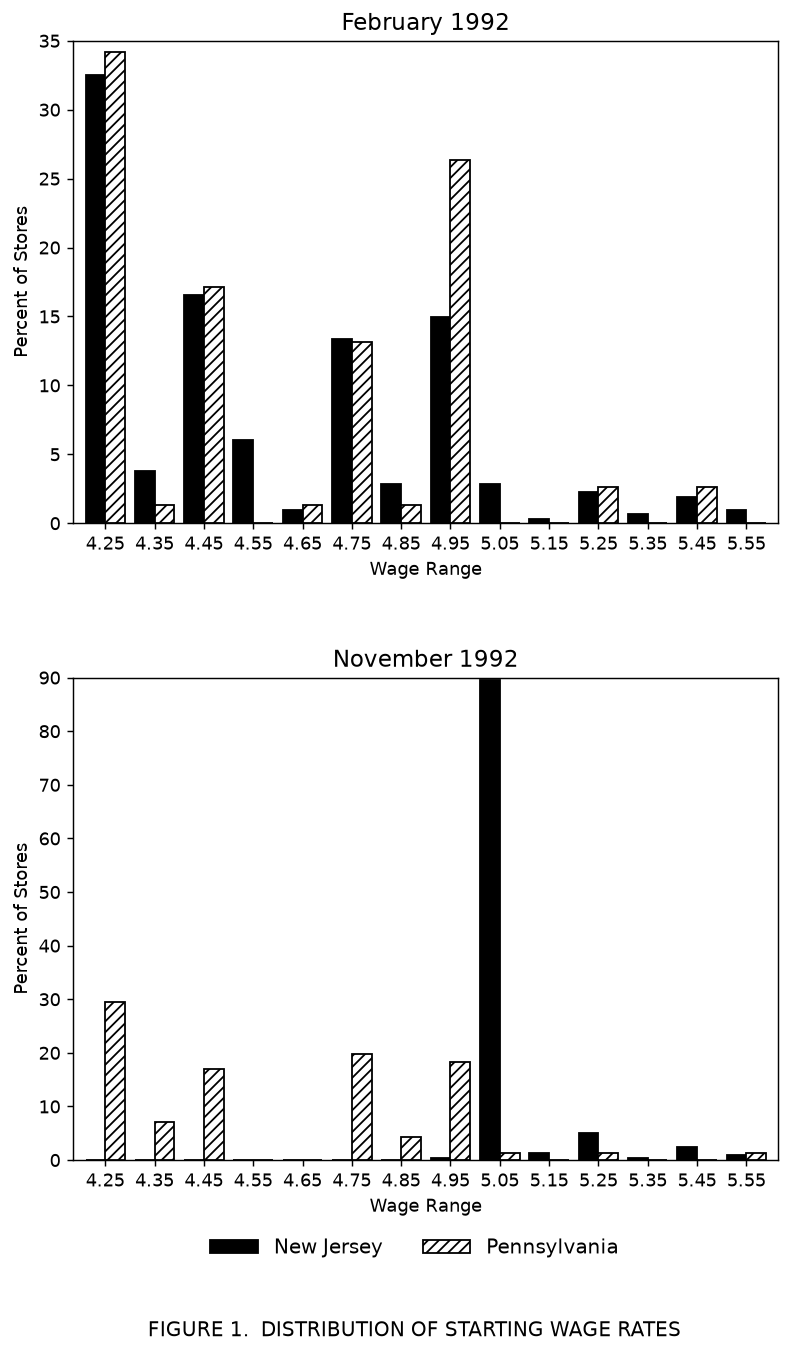

  Wage |      Feb 1992       |      Nov 1992      
       |     NJ %     PA % |     NJ %     PA %
----------------------------------------------------------
  4.25 |    32.48    34.21 |     0.00    29.58
  4.35 |     3.82     1.32 |     0.00     7.04
  4.45 |    16.56    17.11 |     0.00    16.90
  4.55 |     6.05     0.00 |     0.00     0.00
  4.65 |     0.96     1.32 |     0.00     0.00
  4.75 |    13.38    13.16 |     0.00    19.72
  4.85 |     2.87     1.32 |     0.00     4.23
  4.95 |    14.97    26.32 |     0.31    18.31
  5.05 |     2.87     0.00 |    89.62     1.41
  5.15 |     0.32     0.00 |     1.26     0.00
  5.25 |     2.23     2.63 |     5.03     1.41
  5.35 |     0.64     0.00 |     0.31     0.00
  5.45 |     1.91     2.63 |     2.52     0.00
  5.55 |     0.96     0.00 |     0.94     1.41
----------------------------------------------------------
     N |      314       76 |      318       71


In [10]:
# ============================================================
# Figure 1 -- "Distribution of Starting Wage Rates"
# Card & Krueger (1994), AER.
#
#   Top panel   : February 1992 = wave 1  -> WAGE_ST
#   Bottom panel: November 1992 = wave 2  -> WAGE_ST2
#   Solid black : New Jersey   (STATE == 1)
#   Hatched     : Pennsylvania (STATE == 0)
#   X axis      : $0.10 bins, left edges 4.25, 4.35, ..., 5.55
#   Y axis      : PERCENT OF STORES (within each state, not counts)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- wage-bin nodes exactly as printed in the figure -------------
NODES = np.round(np.arange(4.25, 5.55 + 1e-9, 0.10), 2)   # 14 bins
WIDTH = 0.10

def wage_percent(wage, state):
    """Within-state percentage of stores falling in each $0.10 wage bin."""
    wage  = np.asarray(wage,  dtype=float)
    state = np.asarray(state, dtype=float)
    ok = np.isfinite(wage)
    # bin index = floor((wage - 4.25) / 0.10); wages >= 5.55 land in the last bin
    idx = np.clip(np.floor((wage - NODES[0]) / WIDTH + 1e-9).astype(int),
                  0, len(NODES) - 1)
    out = {}
    for name, mask in [("NJ", ok & (state == 1.0)), ("PA", ok & (state == 0.0))]:
        n = int(mask.sum())
        cnt = np.bincount(idx[mask], minlength=len(NODES))
        out[name]   = 100.0 * cnt / n if n else np.zeros(len(NODES))
        out[name + "_n"] = n
    return out

top    = wage_percent(df["WAGE_ST"],  df["STATE"])   # February 1992
bottom = wage_percent(df["WAGE_ST2"], df["STATE"])   # November 1992

# ---- plot --------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(7.0, 10.5), dpi=130)
panels = [(axes[0], top,    "February 1992",  35, 5),
          (axes[1], bottom, "November 1992",  90, 10)]
x = np.arange(len(NODES), dtype=float)
for ax, dat, title, ymax, ystep in panels:
    ax.bar(x - 0.20, dat["NJ"], width=0.40, color="black", edgecolor="black",
           label="New Jersey", zorder=3)
    ax.bar(x + 0.20, dat["PA"], width=0.40, color="white", edgecolor="black",
           hatch="////", label="Pennsylvania", zorder=3)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Wage Range")
    ax.set_ylabel("Percent of Stores")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{v:.2f}" for v in NODES])
    ax.set_xlim(-0.65, len(NODES) - 0.35)
    ax.set_ylim(0, ymax)
    ax.set_yticks(np.arange(0, ymax + 1, ystep))
    ax.tick_params(direction="out")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 0.045), fontsize=11, handlelength=2.4)
fig.suptitle("FIGURE 1.  DISTRIBUTION OF STARTING WAGE RATES",
             y=0.012, fontsize=11)
fig.subplots_adjust(hspace=0.32, bottom=0.13, top=0.95)
plt.show()

# ---- printed numbers, for checking against the paper --------------
print(f"{'Wage':>6s} | {'Feb 1992':^19s} | {'Nov 1992':^19s}")
print(f"{'':6s} | {'NJ %':>8s} {'PA %':>8s} | {'NJ %':>8s} {'PA %':>8s}")
print("-" * 58)
for i, v in enumerate(NODES):
    print(f"{v:6.2f} | {top['NJ'][i]:8.2f} {top['PA'][i]:8.2f} | "
          f"{bottom['NJ'][i]:8.2f} {bottom['PA'][i]:8.2f}")
print("-" * 58)
print(f"{'N':>6s} | {top['NJ_n']:8d} {top['PA_n']:8d} | "
      f"{bottom['NJ_n']:8d} {bottom['PA_n']:8d}")

Independent extension

In [11]:
# ============================================================================
# Independent extension -- DID heterogeneity by store ownership
# ----------------------------------------------------------------------------
#   Dependent variable : delta_fte = FTE(wave 2) - FTE(wave 1)
#   Sample             : identical to the Table 4 replication
#                        (stores with valid wave-1 & wave-2 employment AND
#                         valid wave-1 & wave-2 starting-wage data)
#   FTE                : NMGRS + EMPFT + 0.5 * EMPPT   (managers full weight)
#                        STATUS2 == 3 (permanently closed) -> wave-2 FTE = 0
#   Controls           : chain dummies (KFC, Roy Rogers, Wendy's; Burger King
#                        is the omitted base) and region dummies (SOUTHJ,
#                        CENTRALJ, PA1, PA2)
#   `own` is NOT a control: it is the moderator of interest, so including it
#   in the control block would be collinear with the interaction in Task B.
# ============================================================================
import math
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Variable construction (same rules as Table 2 / 3 / 4)
# ---------------------------------------------------------------------------
fte1 = df["NMGRS"] + df["EMPFT"] + 0.5 * df["EMPPT"]
_fte2_raw = df["NMGRS2"] + df["EMPFT2"] + 0.5 * df["EMPPT2"]
fte2 = pd.Series(np.nan, index=df.index)
fte2[df["STATUS2"] == 1] = _fte2_raw[df["STATUS2"] == 1]   # successfully re-interviewed
fte2[df["STATUS2"] == 3] = 0.0                             # permanently closed -> 0
dE = fte2 - fte1                                           # dependent variable

# sample restriction -- exactly the Table 4 rule
m = (fte1.notna() & fte2.notna()
     & df["WAGE_ST"].notna() & df["WAGE_ST2"].notna()).to_numpy()

def _num(col):
    return pd.to_numeric(df[col], errors="coerce").to_numpy(float)

Y   = dE.to_numpy(float)[m]
NJv = (_num("STATE")[m]    == 1.0).astype(float)   # treat : 1 = NJ, 0 = PA
own = (_num("CO_OWNED")[m] == 1.0).astype(float)   # own   : 1 = company-owned
one = np.ones(Y.size)

chain_m = _num("CHAIN")[m]
CTL = np.column_stack([
    chain_m == 2.0, chain_m == 3.0, chain_m == 4.0,      # KFC, Roy Rogers, Wendy's
    _num("SOUTHJ")[m]   == 1.0,
    _num("CENTRALJ")[m] == 1.0,
    _num("PA1")[m]      == 1.0,
    _num("PA2")[m]      == 1.0,
]).astype(float)

NMS_A = ["const", "treat", "chain: KFC", "chain: Roy Rogers", "chain: Wendy's",
         "region: SOUTHJ", "region: CENTRALJ", "region: PA1", "region: PA2"]
NMS_B = ["const", "treat", "own", "treat x own"] + NMS_A[2:]

# ---------------------------------------------------------------------------
# 2. OLS with Student-t p-values -- no scipy available
#    (same regularised incomplete beta as the Table 4 cell; safe to redefine)
# ---------------------------------------------------------------------------
def _betacf(a, b, x, maxit=300, eps=3e-16, fpmin=1e-300):
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < fpmin: d = fpmin
    d = 1.0 / d; h = d
    for mm in range(1, maxit + 1):
        m2 = 2 * mm
        aa = mm * (b - mm) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d; h *= d * c
        aa = -(a + mm) * (qab + mm) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d
        de = d * c; h *= de
        if abs(de - 1.0) < eps: break
    return h

def _betainc(a, b, x):
    if x <= 0.0: return 0.0
    if x >= 1.0: return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
                  + a * math.log(x) + b * math.log1p(-x))
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b

def t_pvalue(t, dfree):
    """Two-sided p-value of Student's t with `dfree` degrees of freedom."""
    t2 = t * t
    return _betainc(dfree / 2.0, 0.5, dfree / (dfree + t2))

def stars(p):
    if p < 0.01: return "***"
    if p < 0.05: return "**"
    if p < 0.10: return "*"
    return ""

def fit(y, X, names):
    """OLS. The intercept is column 0; any other column that is constant
    inside the estimation sample is collinear with it and is dropped."""
    keep = [0] + [j for j in range(1, X.shape[1]) if X[:, j].std() > 0.0]
    dropped = [names[j] for j in range(X.shape[1]) if j not in keep]
    Xk, nk = X[:, keep], [names[j] for j in keep]
    XtX_inv = np.linalg.pinv(Xk.T @ Xk)
    b = XtX_inv @ (Xk.T @ y)
    r = y - Xk @ b
    rss = float(r @ r)
    dfree = Xk.shape[0] - np.linalg.matrix_rank(Xk)
    se = np.sqrt(np.maximum(np.diag(XtX_inv), 0.0) * (rss / dfree))
    t = np.divide(b, se, out=np.zeros_like(b), where=se > 0.0)
    p = np.array([t_pvalue(v, dfree) for v in t])
    tss = float(((y - y.mean()) ** 2).sum())
    return dict(names=nk, dropped=dropped, b=b, se=se, t=t, p=p, n=int(Xk.shape[0]),
                df=int(dfree), ser=math.sqrt(rss / dfree), r2=1.0 - rss / tss)

# ---------------------------------------------------------------------------
# 3. Task A -- split-sample DID ; Task B -- pooled DID with interaction
# ---------------------------------------------------------------------------
X_sa = np.column_stack([one, NJv, CTL])                      # delta_fte ~ treat + controls
X_B  = np.column_stack([one, NJv, own, NJv * own, CTL])      # + own + treat x own

sel_co, sel_fr = (own == 1.0), (own == 0.0)                  # company-owned / franchisee
rA1 = fit(Y[sel_co], X_sa[sel_co], NMS_A)
rA2 = fit(Y[sel_fr], X_sa[sel_fr], NMS_A)
rB  = fit(Y,         X_B,          NMS_B)
ALL = [rA1, rA2, rB]

print("=" * 78)
print("Independent extension: DID heterogeneity by store ownership")
print("Dependent variable: change in FTE employment (wave 2 - wave 1)")
print(f"Estimation sample : {Y.size} stores "
      f"(NJ {int(NJv.sum())}, PA {int((1 - NJv).sum())}) -- Table 4 sample rules")
print(f"Mean / SD of dep. var.: {Y.mean():.3f} / {Y.std(ddof=1):.3f}")
print("=" * 78)
for a, alab in [(1.0, "NJ"), (0.0, "PA")]:
    for o, olab in [(1.0, "company-owned"), (0.0, "franchisee")]:
        s = (NJv == a) & (own == o)
        if s.sum():
            print(f"  {alab} x {olab:<14s} n = {int(s.sum()):3d}   "
                  f"mean delta_fte = {Y[s].mean():7.3f}")
did_co = Y[(NJv == 1) & (own == 1)].mean() - Y[(NJv == 0) & (own == 1)].mean()
did_fr = Y[(NJv == 1) & (own == 0)].mean() - Y[(NJv == 0) & (own == 0)].mean()
print(f"  raw (unconditional) DID :  company-owned = {did_co:6.3f}   "
      f"franchisee = {did_fr:6.3f}")

# ---- 3a. compact regression table -----------------------------------------
W = 22
HEADS = ["(A1) Company-owned", "(A2) Franchisee-owned", "(B) Pooled + interaction"]

def cells(res, key):
    if key not in res["names"]:
        return ["", ""]
    i = res["names"].index(key)
    return [f"{res['b'][i]:.3f}{stars(res['p'][i])}", f"({res['se'][i]:.3f})"]

def c_row(label, key):
    l1, l2 = f"{label:<26s}", " " * 26
    for res in ALL:
        c = cells(res, key)
        l1 += f"{c[0]:^{W}s}"; l2 += f"{c[1]:^{W}s}"
    print(l1); print(l2)

def s_row(label, fn):
    print(f"{label:<26s}" + "".join(f"{fn(r):^{W}s}" for r in ALL))

print()
print("-" * (26 + 3 * W))
print(f"{'delta_fte':<26s}" + "".join(f"{h:^{W}s}" for h in HEADS))
print("-" * (26 + 3 * W))
c_row("treat (NJ dummy)", "treat")
c_row("own (company-owned)", "own")
c_row("treat x own", "treat x own")
print("-" * (26 + 3 * W))
for k in NMS_A[2:]:
    c_row(k.replace(":", ": "), k)
print("-" * (26 + 3 * W))
s_row("N (observations)", lambda r: f"{r['n']}")
s_row("R-squared",        lambda r: f"{r['r2']:.4f}")
s_row("SER",              lambda r: f"{r['ser']:.3f}")
print("-" * (26 + 3 * W))
print("Standard errors in parentheses.  * p<0.10, ** p<0.05, *** p<0.01")
print("Constant estimated but reported in the detail panel below.")

# ---- 3b. full statistics per model ----------------------------------------
for head, res in zip(HEADS, ALL):
    print()
    print("=" * 78)
    print(f"{head}    N = {res['n']}    df = {res['df']}    "
          f"R2 = {res['r2']:.4f}    SER = {res['ser']:.3f}")
    if res["dropped"]:
        print(f"dropped (constant within this subsample): {', '.join(res['dropped'])}")
    print("=" * 78)
    print(f"{'Variable':<20s}{'Coef.':>10s}{'Std.Err.':>11s}"
          f"{'t-stat':>10s}{'p-value':>11s}")
    print("-" * 78)
    for i, nm in enumerate(res["names"]):
        print(f"{nm:<20s}{res['b'][i]:>10.3f}{res['se'][i]:>11.3f}"
              f"{res['t'][i]:>10.3f}{res['p'][i]:>11.4f}  {stars(res['p'][i])}")
    print("-" * 78)

# ---- 3c. what the interaction means ---------------------------------------
i_tx = rB["names"].index("treat x own")
i_tr = rB["names"].index("treat")
b_tx, se_tx, t_tx, p_tx = rB["b"][i_tx], rB["se"][i_tx], rB["t"][i_tx], rB["p"][i_tx]
print()
print("=" * 78)
print("READING THE INTERACTION TERM  beta3  (column B)")
print("=" * 78)
print(f"  beta3 (treat x own) = {b_tx:.3f}  (SE {se_tx:.3f}),  "
      f"t = {t_tx:.3f},  p = {p_tx:.4f} {stars(p_tx)}".rstrip())
print(f"  implied DID effect, franchisee    (own = 0) : beta1        = {rB['b'][i_tr]:7.3f}")
print(f"  implied DID effect, company-owned (own = 1) : beta1 + beta3 = "
      f"{rB['b'][i_tr] + b_tx:7.3f}")
print("  beta3 is the ADDITIONAL employment effect of the New Jersey minimum-wage")
print("  increase for company-owned stores relative to franchisee-owned stores.")
print("  beta3 = 0 -> ownership does not moderate the policy effect (the two split-")
print("  sample DID estimates would coincide); beta3 > 0 -> the effect is larger in")
print("  company-owned stores; beta3 < 0 -> it is smaller.")
print("=" * 78)

Independent extension: DID heterogeneity by store ownership
Dependent variable: change in FTE employment (wave 2 - wave 1)
Estimation sample : 351 stores (NJ 285, PA 66) -- Table 4 sample rules
Mean / SD of dep. var.: -0.030 / 8.748
  NJ x company-owned  n = 100   mean delta_fte =   0.180
  NJ x franchisee     n = 185   mean delta_fte =   0.516
  PA x company-owned  n =  24   mean delta_fte =  -1.917
  PA x franchisee     n =  42   mean delta_fte =  -1.857
  raw (unconditional) DID :  company-owned =  2.097   franchisee =  2.373

--------------------------------------------------------------------------------------------
delta_fte                   (A1) Company-owned  (A2) Franchisee-owned (B) Pooled + interaction
--------------------------------------------------------------------------------------------
treat (NJ dummy)                 3.395***               1.026                 1.541*        
                                 (1.159)               (1.054)               (0.926)      

In [ ]:
# ============================================================================
# EXPORT ALL TABLES AND FIGURES OF THIS NOTEBOOK TO WORD
# ----------------------------------------------------------------------------
#   1) pip install python-docx        (只装一次)
#   2) Ctrl+S 保存 notebook           (必须先保存，输出才会落到磁盘上)
#   3) 运行本 cell
#   结果：与本 notebook 同目录下生成 replication_report.docx
#
# 原理：读取已保存的 .ipynb，把每个 code cell 的 text 输出（打印出来的表格）
#       和 image/png 输出（Figure 1）按 cell 顺序写入 Word。
#       .ipynb 中保存的是完整输出，notebook 界面上的 "Output is truncated"
#       只是显示层截断，不影响这里取到的内容。
# ============================================================================
import io, json, base64, glob, os
from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH

NB_PATH  = "Table2 过程.ipynb"        # <-- 如果文件名不同，改这里
OUT_PATH = "replication_report.docx"

if not os.path.exists(NB_PATH):       # 文件名对不上时自动在目录里找
    cands = [p for p in glob.glob("*.ipynb") if "checkpoint" not in p]
    if len(cands) == 1:
        NB_PATH = cands[0]
    else:
        raise FileNotFoundError(
            f"'{NB_PATH}' not found in {os.getcwd()}. "
            f"Notebooks here: {cands}. Set NB_PATH manually.")

with open(NB_PATH, "r", encoding="utf-8") as fh:
    nb = json.load(fh)

def as_text(v):
    return "".join(v) if isinstance(v, list) else str(v)

doc = Document()
sec = doc.sections[0]
sec.left_margin = sec.right_margin = Inches(0.7)
doc.add_heading("Card & Krueger (1994) Minimum Wage Study: Replication Output", level=0)
doc.add_paragraph(f"Source notebook: {os.path.basename(NB_PATH)}")

n_txt = n_img = n_cell = 0
for i, cell in enumerate(nb.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue
    src = as_text(cell.get("source", [])).strip()
    texts, pngs = [], []
    for out in cell.get("outputs", []):
        data = out.get("data", {})
        if out.get("output_type") == "stream":          # print() 的输出
            texts.append(as_text(out.get("text", "")))
        if "text/plain" in data:                        # 富文本结果的纯文本形式
            texts.append(as_text(data["text/plain"]))
        if "image/png" in data:                         # matplotlib 图形
            pngs.append(as_text(data["image/png"]))
    if not texts and not pngs:
        continue
    # 用该 cell 源码的第一行作为 Word 里的小标题
    title = src.splitlines()[0][:80] if src else f"Cell {i}"
    doc.add_heading(title, level=2)
    for t in texts:
        if t.strip():
            run = doc.add_paragraph().add_run(t.rstrip())
            run.font.name = "Consolas"
            run.font.size = Pt(8)
            n_txt += 1
    for b in pngs:
        doc.add_picture(io.BytesIO(base64.b64decode(b)), width=Inches(6.4))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        n_img += 1
    n_cell += 1
    doc.add_paragraph()

doc.save(OUT_PATH)
print(f"OK -> {OUT_PATH}   ({n_cell} cells, {n_txt} text blocks, {n_img} figures)")